# EDA SECOP II > Contratos electrónicos

Este notebook analiza los contratos electrónicos de SECOP II correspondientes al periodo seleccionado. Se revisa la calidad de los datos, su distribución territorial, las modalidades de contratación y los valores económicos.

## 1. Configuración

Se define el periodo de análisis y el territorio que se desea consultar. También se establece la conexión con MongoDB.

In [1]:
import os
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from pymongo import MongoClient

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.titlesize"] = 11
plt.rcParams["axes.labelsize"] = 10

# Fuente fija. Solo se configuran año, mes y recorte territorial.
FUENTE = "contratos"
ANIO = 2026
MES = 9
TERRITORIO = "nacional"  # "nacional" o "bogota"
MONGO_DB = "secop"

cfg = {
    "nombre": "SECOP II Contratos Electrónicos",
    "dataset_id": "jbjy-vk9h",
    "fecha": "fecha_de_firma",
    "pk": "id_contrato",
    "pk_fila": "socrata_id",
    "coleccion": "contratos_electronicos_raw",
    "valor": "valor_del_contrato",
    "depto": "departamento",
    "muni": "ciudad",
    "entidad": "nombre_entidad",
    "proveedor": "proveedor_adjudicado",
    "modalidad": "modalidad_de_contratacion",
}

inicio = date(ANIO, MES, 1)
fin = date(ANIO + 1, 1, 1) if MES == 12 else date(ANIO, MES + 1, 1)
START_DATE = inicio.isoformat()
END_DATE = fin.isoformat()
PERIODO = f"{ANIO:04d}-{MES:02d}"

NB_DIR = Path("/home/jovyan/work/spark-apps/notebooks")
if not NB_DIR.exists():
    NB_DIR = Path.cwd()
SALIDAS = NB_DIR / "salidas" / PERIODO / FUENTE
FIGURAS = SALIDAS / "figuras"
SALIDAS.mkdir(parents=True, exist_ok=True)
FIGURAS.mkdir(parents=True, exist_ok=True)


def guardar_fig(nombre):
    plt.tight_layout()
    plt.savefig(FIGURAS / nombre, dpi=120, bbox_inches="tight")
    print("Figura:", nombre)


def nulos_o_vacios(s):
    if s.dtype == object or str(s.dtype) == "string":
        txt = s.astype(str).str.strip()
        return s.isna() | txt.eq("") | txt.str.lower().isin(["nan", "none", "null"])
    return s.isna()


def es_bogota(serie):
    return serie.astype(str).str.lower().str.contains("bogot|distrito capital", regex=True, na=False)


uri = os.environ.get("MONGO_URI")
if not uri:
    raise RuntimeError("Falta MONGO_URI en el entorno del contenedor.")
client = MongoClient(uri, serverSelectionTimeoutMS=10000)
client.admin.command("ping")
db = client[MONGO_DB]
print("MongoDB: OK |", cfg["nombre"], "|", PERIODO, "|", TERRITORIO)
print("Colección:", cfg["coleccion"])


MongoDB: OK | SECOP II Contratos Electrónicos | 2026-09 | nacional
Colección: contratos_electronicos_raw


## 2. Carga

Se consultan los contratos almacenados en MongoDB y se seleccionan los correspondientes al periodo de análisis, sin modificar los registros originales.

In [2]:
col = db[cfg["coleccion"]]
if cfg["coleccion"] not in db.list_collection_names():
    raise RuntimeError(
        f"No existe {cfg['coleccion']}. Ejecute 03_ingesta_contratos.ipynb."
    )

n_hist = db["contratos_raw"].estimated_document_count() if "contratos_raw" in db.list_collection_names() else 0
df = pd.DataFrame(list(col.find({"_periodo": PERIODO})))
if df.empty:
    raise RuntimeError(
        f"No hay documentos de {PERIODO} en {cfg['coleccion']}. Ejecute 03_ingesta_contratos.ipynb."
    )

df["fecha_ref"] = pd.to_datetime(df.get(cfg["fecha"]), errors="coerce")
df = df[(df["fecha_ref"] >= START_DATE) & (df["fecha_ref"] < END_DATE)].copy()
depto_col = cfg["depto"] if cfg["depto"] in df.columns else None
df["_es_bogota"] = es_bogota(df[depto_col]) if depto_col else False
n_nacional = len(df)
n_bta = int(df["_es_bogota"].sum())
n_fila = df[cfg["pk_fila"]].nunique(dropna=True) if cfg["pk_fila"] in df.columns else 0
n_pk = df[cfg["pk"]].nunique(dropna=True) if cfg["pk"] in df.columns else 0

if TERRITORIO.lower() == "bogota":
    df = df[df["_es_bogota"]].copy()
    print("Filtro: Bogotá / Distrito Capital")

print("Filas:", f"{len(df):,}".replace(",", "."))
print("socrata_id distintas:", f"{n_fila:,}".replace(",", "."), "| id_contrato distintas:", f"{n_pk:,}".replace(",", "."))
print("Nacional:", f"{n_nacional:,}".replace(",", "."), "| Bogotá (recorte):", f"{n_bta:,}".replace(",", "."))
print("Periodo real:", df["fecha_ref"].min(), "→", df["fecha_ref"].max())
print("contratos_raw (sin tocar):", f"{n_hist:,}".replace(",", "."))
print("Un contrato electrónico no equivale a un proceso SECOP II.")
display(df.drop(columns=["_id"], errors="ignore").head(5))


Filas: 82.964
socrata_id distintas: 82.964 | id_contrato distintas: 82.964
Nacional: 82.964 | Bogotá (recorte): 11.272
Periodo real: 2026-09-01 00:00:59.900000 → 2026-09-30 23:58:33.504000
contratos_raw (sin tocar): 288.261
Un contrato electrónico no equivale a un proceso SECOP II.


,socrata_id,:id,_dataset_id,_fuente,_ingestion_ts,_nivel,_periodo,ciudad,codigo_de_categoria_principal,codigo_entidad,...,valor_amortizado,valor_de_pago_adelantado,valor_del_contrato,valor_facturado,valor_pagado,valor_pendiente_de,valor_pendiente_de_ejecucion,valor_pendiente_de_pago,fecha_ref,_es_bogota
0,row-cqqu_42dm.vp26,row-cqqu_42dm.vp26,jbjy-vk9h,contratos,2026-10-26 14:01:49.376,filas,2026-09,Villavicencio,V1.80111600,700817075,...,0,0,9183333,0,0,0,9183333,9183333,2026-09-09 16:45:22.175,False
1,row-252j~3eaq_pey4,row-252j~3eaq_pey4,jbjy-vk9h,contratos,2026-10-26 14:01:49.376,filas,2026-09,No Definido,V1.80111600,706081700,...,0,0,23200000,0,0,0,23200000,23200000,2026-09-03 19:32:05.377,True
2,row-jzbw-5ys6_6bfm,row-jzbw-5ys6_6bfm,jbjy-vk9h,contratos,2026-10-26 14:01:49.376,filas,2026-09,Cúcuta,V1.80111600,700445042,...,0,0,14666666.67,0,0,0,14666666.67,14666666.67,2026-09-07 19:33:43.453,False
3,row-9bcv-twws-faqp,row-9bcv-twws-faqp,jbjy-vk9h,contratos,2026-10-26 14:01:49.376,filas,2026-09,No Definido,UNSPECIFIED,702184359,...,0,0,0,0,0,0,0,0,2026-09-29 16:56:14.457,True
4,row-udgd~69vp-adrd,row-udgd~69vp-adrd,jbjy-vk9h,contratos,2026-10-26 14:01:49.376,filas,2026-09,Balboa,UNSPECIFIED,706857505,...,0,0,8229000,2743000,0,0,8229000,8229000,2026-09-18 18:21:20.480,False


## 3. Calidad

Se revisan los valores faltantes, los registros duplicados, las fechas y los valores de los contratos para identificar posibles problemas en la información.

In [3]:
cols_clave = [cfg["pk_fila"], cfg["pk"], cfg["fecha"], cfg["valor"], cfg["depto"], cfg["muni"],
              cfg["entidad"], cfg["proveedor"], cfg["modalidad"]]
n = len(df)
valor = pd.to_numeric(df[cfg["valor"]], errors="coerce") if cfg["valor"] in df.columns else pd.Series(dtype=float)

resumen = pd.Series({
    "fuente": FUENTE,
    "dataset": cfg["dataset_id"],
    "filas": n,
    "socrata_id": n_fila,
    "pk_distintas": n_pk,
    "duplicados_fila": n - n_fila,
    "duplicados_pk": n - n_pk,
    "fecha_min": df["fecha_ref"].min(),
    "fecha_max": df["fecha_ref"].max(),
    "fechas_nulas": int(df["fecha_ref"].isna().sum()),
    "departamentos": df[cfg["depto"]].nunique(dropna=True) if cfg["depto"] in df.columns else 0,
    "municipios": df[cfg["muni"]].nunique(dropna=True) if cfg["muni"] in df.columns else 0,
    "entidades": df[cfg["entidad"]].nunique(dropna=True) if cfg["entidad"] in df.columns else 0,
    "proveedores": df[cfg["proveedor"]].nunique(dropna=True) if cfg["proveedor"] in df.columns else 0,
    "bogota": n_bta,
    "pct_bogota": round(100 * n_bta / n_nacional, 2) if n_nacional else 0,
    "valor_mediana": float(valor.median()) if valor.notna().any() else np.nan,
    "valor_p95": float(valor.quantile(0.95)) if valor.notna().any() else np.nan,
    "valor_max": float(valor.max()) if valor.notna().any() else np.nan,
    "valor_cero": int((valor == 0).sum()) if valor.notna().any() else 0,
    "valor_negativo": int((valor < 0).sum()) if valor.notna().any() else 0,
})
display(resumen.to_frame("valor"))
resumen.to_frame("valor").to_csv(SALIDAS / "resumen.csv")

nulos = []
for c in cols_clave:
    if c not in df.columns:
        nulos.append({"campo": c, "nulos_o_vacios": n, "pct": 100.0, "existe": False})
        continue
    nv = int(nulos_o_vacios(df[c]).sum())
    nulos.append({"campo": c, "nulos_o_vacios": nv, "pct": round(100 * nv / n, 2) if n else 0, "existe": True})
tab_nulos = pd.DataFrame(nulos)
display(tab_nulos)
tab_nulos.to_csv(SALIDAS / "nulos.csv", index=False)
print("Duplicados de", cfg["pk_fila"] + ":", n - n_fila)
print("Duplicados de", cfg["pk"] + ":", n - n_pk)


,valor
fuente,contratos
dataset,jbjy-vk9h
filas,82964
socrata_id,82964
pk_distintas,82964
duplicados_fila,0
duplicados_pk,0
fecha_min,2026-09-01 00:00:59.900000
fecha_max,2026-09-30 23:58:33.504000
fechas_nulas,0


,campo,nulos_o_vacios,pct,existe
0,socrata_id,0,0.0,True
1,id_contrato,0,0.0,True
2,fecha_de_firma,0,0.0,True
3,valor_del_contrato,0,0.0,True
4,departamento,0,0.0,True
5,ciudad,0,0.0,True
6,nombre_entidad,0,0.0,True
7,proveedor_adjudicado,0,0.0,True
8,modalidad_de_contratacion,0,0.0,True


Duplicados de socrata_id: 0
Duplicados de id_contrato: 0


## 4. Territorio, modalidades, entidades y proveedores

Se analiza la cantidad de contratos por departamento, municipio, modalidad de contratación, entidad y proveedor.

In [4]:
depto = df[cfg["depto"]].fillna("No Definido").astype(str).value_counts().head(15) if cfg["depto"] in df.columns else pd.Series(dtype=int)
muni = df[cfg["muni"]].fillna("No Definido").astype(str).value_counts().head(15) if cfg["muni"] in df.columns else pd.Series(dtype=int)
mod = df[cfg["modalidad"]].fillna("No Definido").astype(str).value_counts().head(15) if cfg["modalidad"] in df.columns else pd.Series(dtype=int)
ent = df[cfg["entidad"]].fillna("No Definido").astype(str).value_counts().head(15) if cfg["entidad"] in df.columns else pd.Series(dtype=int)
prv = df[cfg["proveedor"]].fillna("No Definido").astype(str).value_counts().head(15) if cfg["proveedor"] in df.columns else pd.Series(dtype=int)

print("Departamentos")
display(depto.to_frame("n"))
print("Municipios")
display(muni.to_frame("n"))
print("Modalidades")
display(mod.to_frame("n"))
print("Entidades")
display(ent.to_frame("n"))
print("Proveedores")
display(prv.to_frame("n"))

depto.rename("n").to_csv(SALIDAS / "departamentos.csv")
muni.rename("n").to_csv(SALIDAS / "municipios.csv")
mod.rename("n").to_csv(SALIDAS / "modalidades.csv")
ent.rename("n").to_csv(SALIDAS / "entidades.csv")
prv.rename("n").to_csv(SALIDAS / "proveedores.csv")


Departamentos


,n
departamento,
Distrito Capital de Bogotá,11272
Antioquia,9093
Valle del Cauca,8735
Santander,5107
Bolívar,5001
Cundinamarca,3997
Risaralda,3447
Tolima,3199
Atlántico,3020


Municipios


,n
ciudad,
No Definido,11918
Bogotá,5965
Cali,5255
Medellín,4177
Cartagena,3030
Pereira,2908
Bucaramanga,2459
Barranquilla,2220
Villavicencio,2098


Modalidades


,n
modalidad_de_contratacion,
Contratación directa,65812
Contratación régimen especial,10023
Mínima cuantía,3666
Selección Abreviada de Menor Cuantía,906
Contratación Directa (con ofertas),743
Contratación régimen especial (con ofertas),694
Selección abreviada subasta inversa,642
Concurso de méritos abierto,195
Licitación pública,140


Entidades


,n
nombre_entidad,
ALCALDÍA DEL DISTRITO TURÍSTICO Y CULTURAL DE CARTAGENA DE INDIAS,2282
INSTITUCIÓN UNIVERSITARIA ITM,1940
MUNICIPIO DE PEREIRA- OFICIAL,1683
MUNICIPIO DE ARMENIA QUINDIO,1155
(Secretaría Distrital de Integración Social),1133
DISTRITO ESPECIAL INDUSTRIAL Y PORTUARIO DE BARRANQUILLA,1051
MUNICIPIO DE BUCARAMANGA,1043
ALCALDIA MUNICIPAL DE VALLEDUPAR,1019
SUBRED INTEGRADA DE SERVICIOS DE SALUD SUR E.S.E.**,747


Proveedores


,n
proveedor_adjudicado,
Aseguradora Solidaria de Colombia Entidad Cooperativa.,55
LA PREVISORA S.A. COMPAÑÍA DE SEGUROS,48
INSTITUTO COLOMBIANO DE NORMAS TÉCNICAS Y CERTIFICACIÓN,37
persona natural,31
Persona Natural,28
CONGREGACION DE RELIGIOSOS TERCIARIOS CAPUCHINOS DE NUESTRA SEÑORA DE LOS DOLORES,20
INSTITUTO PSICEDUCATIVO DE COLOMBIA - IPSICOL,18
SERVICIOS POSTALES NACIONALES S.A.S,18
ASOCIACIÓN DE ENTES DEPORTIVOS DEL SUROESTE ANTIOQUEÑO,17


## 5. Gráficos

Se presentan gráficos para visualizar la distribución de los contratos y facilitar la identificación de patrones en la información.

Figura: departamentos.png


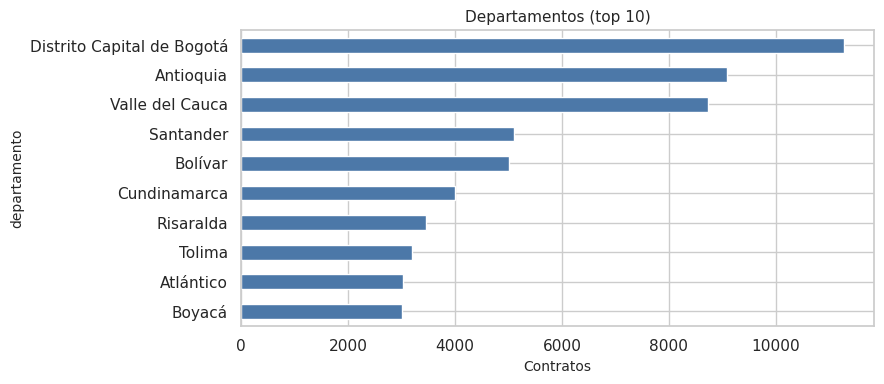

Figura: modalidades.png


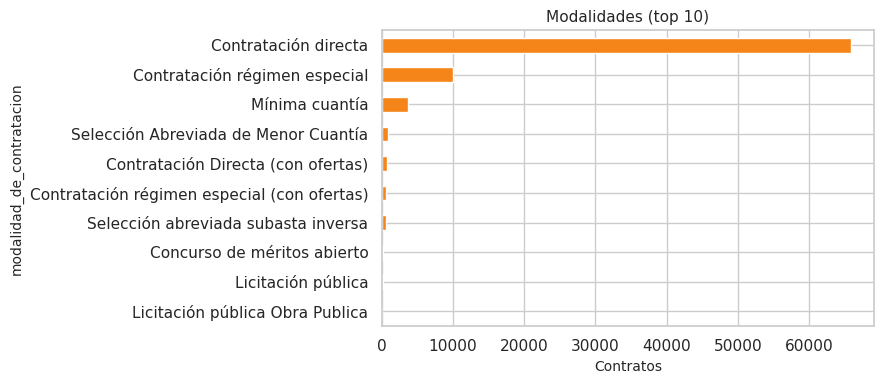

Figura: diario.png


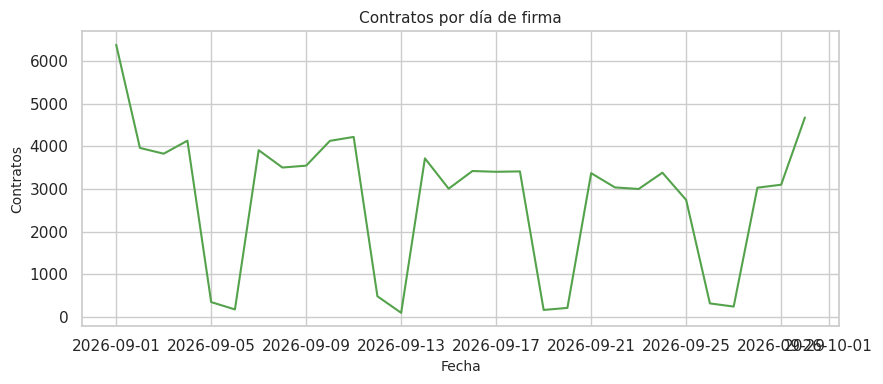

Figura: valor.png


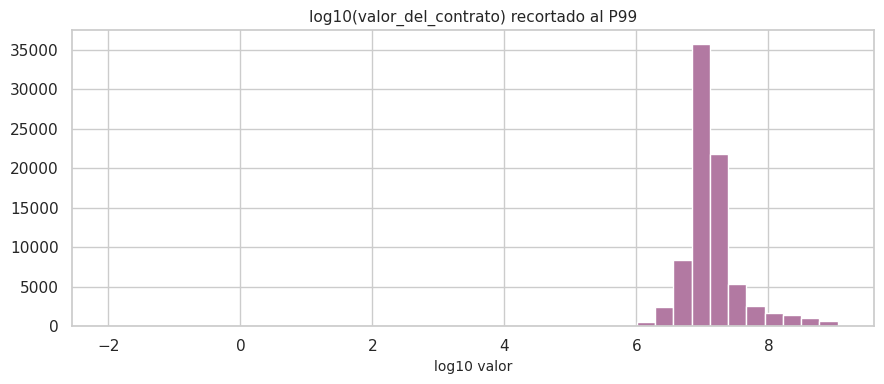

In [5]:
if len(depto):
    fig, ax = plt.subplots()
    depto.head(10).sort_values().plot(kind="barh", ax=ax, color="#4C78A8")
    ax.set_title("Departamentos (top 10)")
    ax.set_xlabel("Contratos")
    guardar_fig("departamentos.png")
    plt.show()

if len(mod):
    fig, ax = plt.subplots()
    mod.head(10).sort_values().plot(kind="barh", ax=ax, color="#F58518")
    ax.set_title("Modalidades (top 10)")
    ax.set_xlabel("Contratos")
    guardar_fig("modalidades.png")
    plt.show()

serie = df.dropna(subset=["fecha_ref"]).groupby(df["fecha_ref"].dt.date).size()
fig, ax = plt.subplots()
serie.plot(ax=ax, color="#54A24B")
ax.set_title("Contratos por día de firma")
ax.set_xlabel("Fecha")
ax.set_ylabel("Contratos")
guardar_fig("diario.png")
plt.show()

val = valor.dropna()
val = val[(val > 0) & (val < val.quantile(0.99))] if not val.empty else val
if not val.empty:
    fig, ax = plt.subplots()
    ax.hist(np.log10(val), bins=40, color="#B279A2")
    ax.set_title(f"log10({cfg['valor']}) recortado al P99")
    ax.set_xlabel("log10 valor")
    guardar_fig("valor.png")
    plt.show()


## 6. Bogotá

Se analizan los contratos correspondientes a Bogotá, identificando sus principales características dentro del conjunto de datos nacional.


In [6]:
tab_bta = pd.DataFrame([{
    "fuente": cfg["nombre"],
    "nacional": n_nacional,
    "bogota": n_bta,
    "pct_bogota": round(100 * n_bta / n_nacional, 2) if n_nacional else 0,
}])
display(tab_bta)
tab_bta.to_csv(SALIDAS / "bogota.csv", index=False)
print("Recorte territorial. No se compara con el Portal de Transparencia ni con procesos.")


,fuente,nacional,bogota,pct_bogota
0,SECOP II Contratos Electrónicos,82964,11272,13.59


Recorte territorial. No se compara con el Portal de Transparencia ni con procesos.


## 7. Territorio, ceros y extremos

Se revisa la información territorial y los valores de los contratos para identificar registros sin ubicación definida, valores iguales a cero y montos elevados que requieren revisión.


In [7]:
depto_all = df[cfg["depto"]].fillna("No Definido").astype(str) if cfg["depto"] in df.columns else pd.Series(["No Definido"] * len(df))
tab_depto = depto_all.value_counts().rename("n").to_frame()
tab_depto["pct"] = (100 * tab_depto["n"] / len(df)).round(2)
print("Categorías territoriales:", len(tab_depto))
display(tab_depto.head(20))
tab_depto.to_csv(SALIDAS / "territorios.csv")

nd = df[depto_all.eq("No Definido")].copy()
print("No Definido:", f"{len(nd):,}".replace(",", "."))

ceros = df[valor.eq(0)].copy()
print("valor_del_contrato = 0:", f"{len(ceros):,}".replace(",", "."))
p99 = float(valor.quantile(0.99)) if valor.notna().any() else 0
extremos = df[valor > 1e12].copy()
print("P99 valor_del_contrato:", f"{p99:,.0f}".replace(",", "."))
print("valor_del_contrato > 1e12:", len(extremos))
cols_show = [c for c in [cfg["pk"], cfg["entidad"], cfg["depto"], cfg["modalidad"], cfg["valor"]] if c in df.columns]
top = df.assign(_v=valor).nlargest(8, "_v")
display(top[cols_show])
top[cols_show].to_csv(SALIDAS / "valores_extremos.csv", index=False)


Categorías territoriales: 34


,n,pct
departamento,,
Distrito Capital de Bogotá,11272,13.59
Antioquia,9093,10.96
Valle del Cauca,8735,10.53
Santander,5107,6.16
Bolívar,5001,6.03
Cundinamarca,3997,4.82
Risaralda,3447,4.15
Tolima,3199,3.86
Atlántico,3020,3.64


No Definido: 1.454
valor_del_contrato = 0: 506
P99 valor_del_contrato: 1.114.162.206
valor_del_contrato > 1e12: 1


,id_contrato,nombre_entidad,departamento,modalidad_de_contratacion,valor_del_contrato
27780,CO1.PCCNTR.9953923,INSTITUTO DE DEPORTES Y RECREACION DE MEDELLIN,Antioquia,Contratación directa,1159397606948
57135,CO1.PCCNTR.9907542,TRANSMILENIO S.A.,Distrito Capital de Bogotá,Licitación pública,310471072929.45
76053,CO1.PCCNTR.9991604,ALCALDIA DE SANTO TOMAS; ATLANTICO,Atlántico,Contratación directa,282523591100
39522,CO1.PCCNTR.9722209,DEPARTAMENTO DE CORDOBA,Córdoba,Licitación pública Obra Publica,231391628537
26201,CO1.PCCNTR.9905041,INSTITUTO DE DEPORTES Y RECREACION DE MEDELLIN,Antioquia,Contratación directa,124051949378
60038,CO1.PCCNTR.9920618,DEPARTAMENTO DE SANTANDER,Santander,Licitación pública,119826846340
28400,CO1.PCCNTR.9942511,INSTITUTO DE DEPORTES Y RECREACION DE MEDELLIN,Antioquia,Contratación directa,110000000000
55869,CO1.PCCNTR.9888728,FONDO MIXTO DE INNOVACION Y DESARROLLO SOCIAL ...,Casanare,Contratación régimen especial,104604909072


## 8. Reglas

Se establecen recomendaciones para el tratamiento de los datos durante la etapa de transformación, considerando la información territorial, los valores en cero y los valores extremos. Estas reglas aún no se aplican y los registros originales se conservan sin modificaciones.

In [8]:
reglas = pd.DataFrame([
    {"id": "C1", "regla": "Clave de fila: socrata_id. Clave de negocio: id_contrato. Un contrato no es un proceso."},
    {"id": "C2", "regla": "No consolidar filas en la ingesta. Deduplicar solo en derivados o Spark."},
    {"id": "C3", "regla": "Fecha de análisis: fecha_de_firma."},
    {"id": "C4", "regla": "valor_del_contrato a numérico. Marcar 0, negativos y > 1e12 como sospechosos, no como irregularidad."},
    {"id": "C5", "regla": "Homologar Bogotá / Distrito Capital como recorte territorial. No comparar con el Portal."},
    {"id": "C6", "regla": "No cruzar 1:1 con procesos_filas_api: no son el mismo universo."},
    {"id": "C7", "regla": "Limpieza solo en derivados. No escribir en contratos_raw ni contratos_electronicos_raw."},
])
display(reglas)
reglas.to_csv(SALIDAS / "reglas_limpieza.csv", index=False)
print("Salidas:", SALIDAS)


,id,regla
0,C1,Clave de fila: socrata_id. Clave de negocio: i...
1,C2,No consolidar filas en la ingesta. Deduplicar ...
2,C3,Fecha de análisis: fecha_de_firma.
3,C4,"valor_del_contrato a numérico. Marcar 0, negat..."
4,C5,Homologar Bogotá / Distrito Capital como recor...
5,C6,No cruzar 1:1 con procesos_filas_api: no son e...
6,C7,Limpieza solo en derivados. No escribir en con...


Salidas: /home/jovyan/work/spark-apps/notebooks/salidas/2026-09/contratos
